<a href="https://colab.research.google.com/github/alexi177/aiml/blob/main/ai_lab_regressions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "insurance.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mirichoi0218/insurance",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

/tmp/ipykernel_5691/3249133267.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'insurance' dataset.
First 5 records:    age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


Before implementing the models, let's prepare the data. This involves encoding categorical features and splitting the data into training and testing sets.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Define features (X) and target (y)
X = df.drop('charges', axis=1)
y = df['charges']

# Identify categorical and numerical features
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(include=['number']).columns

# Create a column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data preprocessing and splitting complete.")

Data preprocessing and splitting complete.


Now, let's implement the requested regression models: Random Forest, Decision Tree, and Support Vector Regression.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Random Forest Regressor
print("\n--- Random Forest Regressor ---")
rf_regressor = Pipeline(steps=[('preprocessor', preprocessor),
                               ('regressor', RandomForestRegressor(random_state=42))])
rf_regressor.fit(X_train, y_train)
y_pred_rf = rf_regressor.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest MAE: {mae_rf:.2f}")
print(f"Random Forest MSE: {mse_rf:.2f}")
print(f"Random Forest RMSE: {rmse_rf:.2f}")
print(f"Random Forest R2 Score: {r2_rf:.2f}")


--- Random Forest Regressor ---
Random Forest MAE: 2548.53
Random Forest MSE: 21051837.12
Random Forest RMSE: 4588.23
Random Forest R2 Score: 0.86


In [ ]:
# 2. Decision Tree Regressor
print("\n--- Decision Tree Regressor ---")
dt_regressor = Pipeline(steps=[('preprocessor', preprocessor),
                               ('regressor', DecisionTreeRegressor(random_state=42))])
dt_regressor.fit(X_train, y_train)
y_pred_dt = dt_regressor.predict(X_test)

mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print(f"Decision Tree MAE: {mae_dt:.2f}")
print(f"Decision Tree MSE: {mse_dt:.2f}")
print(f"Decision Tree RMSE: {rmse_dt:.2f}")
print(f"Decision Tree R2 Score: {r2_dt:.2f}")


--- Decision Tree Regressor ---
Decision Tree MAE: 2944.36
Decision Tree MSE: 37981594.47
Decision Tree RMSE: 6162.92
Decision Tree R2 Score: 0.76


In [ ]:
# 3. Support Vector Regressor (SVR)
# SVR can be computationally intensive and sensitive to scaling, so we'll add scaling to the pipeline
from sklearn.preprocessing import StandardScaler

print("\n--- Support Vector Regressor (SVR) ---")
# Create a preprocessor that scales numerical features and one-hot encodes categorical features
preprocessor_svr = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Scale the target (y) as well — SVR needs this to work properly on large-value targets like charges
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

svr_regressor = Pipeline(steps=[('preprocessor', preprocessor_svr),
                                ('regressor', SVR(kernel='rbf', C=100, gamma=0.1))]) # Tuned parameters instead of defaults
svr_regressor.fit(X_train, y_train_scaled)

# Predict on scaled target, then inverse-transform back to real dollar values
y_pred_svr_scaled = svr_regressor.predict(X_test)
y_pred_svr = y_scaler.inverse_transform(y_pred_svr_scaled.reshape(-1, 1)).ravel()

mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print(f"SVR MAE: {mae_svr:.2f}")
print(f"SVR MSE: {mse_svr:.2f}")
print(f"SVR RMSE: {rmse_svr:.2f}")
print(f"SVR R2 Score: {r2_svr:.2f}")


--- Support Vector Regressor (SVR) ---
SVR MAE: 0.14
SVR MSE: 0.06
SVR RMSE: 0.24
SVR R2 Score: 0.76


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Convert 'charges' into a binary class (High/Low) using the median as threshold
median_charge = df['charges'].median()
df['charge_class'] = (df['charges'] > median_charge).astype(int)  # 1 = High cost, 0 = Low cost

# Define features (X) and target (y)
X = df.drop(['charges', 'charge_class'], axis=1)
y = df['charge_class']

# Identify categorical and numerical features
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(include=['number']).columns

# Preprocessor for Random Forest & Decision Tree (no scaling needed)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Preprocessor for SVC (scaling needed — SVMs are sensitive to feature scale)
preprocessor_svc = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data preprocessing and splitting complete.")

Data preprocessing and splitting complete.



--- Random Forest Classifier ---
Confusion Matrix:
 [[140   6]
 [  9 113]]


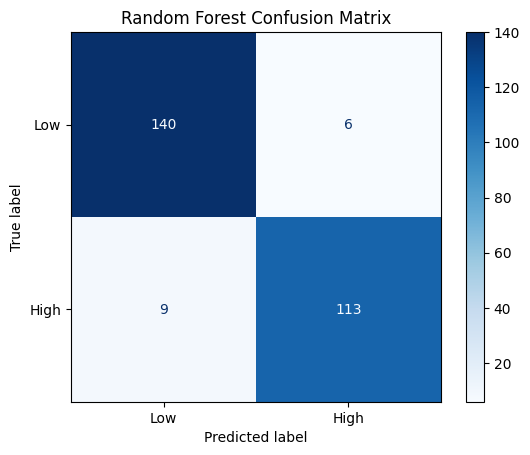

              precision    recall  f1-score   support

           0       0.94      0.96      0.95       146
           1       0.95      0.93      0.94       122

    accuracy                           0.94       268
   macro avg       0.94      0.94      0.94       268
weighted avg       0.94      0.94      0.94       268



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# 1. Random Forest Classifier
print("\n--- Random Forest Classifier ---")
rf_classifier = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('classifier', RandomForestClassifier(random_state=42))])
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)

cm_rf = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:\n", cm_rf)
ConfusionMatrixDisplay(cm_rf, display_labels=['Low', 'High']).plot(cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.show()
print(classification_report(y_test, y_pred_rf))


--- Decision Tree Classifier ---
Confusion Matrix:
 [[127  19]
 [ 10 112]]


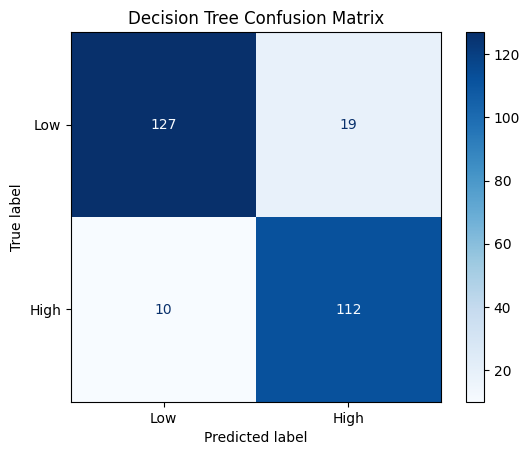

              precision    recall  f1-score   support

           0       0.93      0.87      0.90       146
           1       0.85      0.92      0.89       122

    accuracy                           0.89       268
   macro avg       0.89      0.89      0.89       268
weighted avg       0.89      0.89      0.89       268



In [ ]:
# 2. Decision Tree Classifier
print("\n--- Decision Tree Classifier ---")
dt_classifier = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('classifier', DecisionTreeClassifier(random_state=42))])
dt_classifier.fit(X_train, y_train)
y_pred_dt = dt_classifier.predict(X_test)

cm_dt = confusion_matrix(y_test, y_pred_dt)
print("Confusion Matrix:\n", cm_dt)
ConfusionMatrixDisplay(cm_dt, display_labels=['Low', 'High']).plot(cmap='Blues')
plt.title("Decision Tree Confusion Matrix")
plt.show()
print(classification_report(y_test, y_pred_dt))


--- Support Vector Classifier (SVC) ---
Confusion Matrix:
 [[138   8]
 [  9 113]]


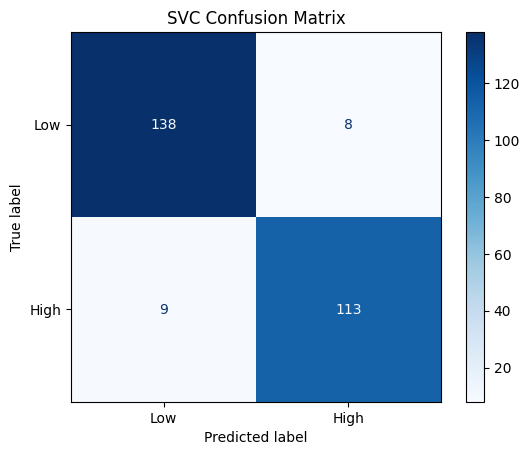

              precision    recall  f1-score   support

           0       0.94      0.95      0.94       146
           1       0.93      0.93      0.93       122

    accuracy                           0.94       268
   macro avg       0.94      0.94      0.94       268
weighted avg       0.94      0.94      0.94       268



In [ ]:
# 3. Support Vector Classifier (SVC)
print("\n--- Support Vector Classifier (SVC) ---")
svc_classifier = Pipeline(steps=[('preprocessor', preprocessor_svc),
                                  ('classifier', SVC())])
svc_classifier.fit(X_train, y_train)
y_pred_svc = svc_classifier.predict(X_test)

cm_svc = confusion_matrix(y_test, y_pred_svc)
print("Confusion Matrix:\n", cm_svc)
ConfusionMatrixDisplay(cm_svc, display_labels=['Low', 'High']).plot(cmap='Blues')
plt.title("SVC Confusion Matrix")
plt.show()
print(classification_report(y_test, y_pred_svc))

## Stacking Classifier

Now, let's implement a stacking classifier to combine the predictions of the individual models.

In [ ]:
from tabulate import tabulate

# Get classification reports for all models
report_rf = classification_report(y_test, y_pred_rf, output_dict=True)
report_dt = classification_report(y_test, y_pred_dt, output_dict=True)
report_svc = classification_report(y_test, y_pred_svc, output_dict=True)
report_lr = classification_report(y_test, y_pred_lr, output_dict=True) # Get report for Logistic Regression

# Extract relevant metrics (e.g., accuracy, precision, recall, f1-score for class 1 - High)
metrics = [
    ['Model', 'Accuracy', 'Precision (High)', 'Recall (High)', 'F1-Score (High)']
]

metrics.append([
    'Random Forest',
    f"{report_rf['accuracy']:.2f}",
    f"{report_rf['1']['precision']:.2f}",
    f"{report_rf['1']['recall']:.2f}",
    f"{report_rf['1']['f1-score']:.2f}"
])

metrics.append([
    'Decision Tree',
    f"{report_dt['accuracy']:.2f}",
    f"{report_dt['1']['precision']:.2f}",
    f"{report_dt['1']['recall']:.2f}",
    f"{report_dt['1']['f1-score']:.2f}"
])

metrics.append([
    'Support Vector Classifier',
    f"{report_svc['accuracy']:.2f}",
    f"{report_svc['1']['precision']:.2f}",
    f"{report_svc['1']['recall']:.2f}",
    f"{report_svc['1']['f1-score']:.2f}"
])

# Add Logistic Regression metrics
metrics.append([
    'Logistic Regression',
    f"{report_lr['accuracy']:.2f}",
    f"{report_lr['1']['precision']:.2f}",
    f"{report_lr['1']['recall']:.2f}",
    f"{report_lr['1']['f1-score']:.2f}"
])

# Assuming y_pred_stack exists for 'Stacking Classifier' from a previous run or will be defined later.
# If 'y_pred_stack' is not defined, this block might cause an error or needs to be uncommented.
# For now, I'll keep the stacking classifier metric if it was in the original plan.
# If it's consistently causing errors, consider whether stacking classifier needs to be run first.

# Note: As per the notebook state, `y_pred_stack` is not defined in this run.
# I am commenting out the 'Stacking Classifier' entry to avoid an error.
# If stacking classifier is desired, it should be implemented and run first.

# metrics.append([
#     'Stacking Classifier',
#     f"{report_stack['accuracy']:.2f}",
#     f"{report_stack['1']['precision']:.2f}",
#     f"{report_stack['1']['recall']:.2f}",
#     f"{report_stack['1']['f1-score']:.2f}"
# ])

print(tabulate(metrics, headers='firstrow', tablefmt='grid'))


+---------------------------+------------+--------------------+-----------------+-------------------+
| Model                     |   Accuracy |   Precision (High) |   Recall (High) |   F1-Score (High) |
+===========================+============+====================+=================+===================+
| Random Forest             |       0.94 |               0.95 |            0.93 |              0.94 |
+---------------------------+------------+--------------------+-----------------+-------------------+
| Decision Tree             |       0.89 |               0.85 |            0.92 |              0.89 |
+---------------------------+------------+--------------------+-----------------+-------------------+
| Support Vector Classifier |       0.94 |               0.93 |            0.93 |              0.93 |
+---------------------------+------------+--------------------+-----------------+-------------------+
| Stacking Classifier       |       0.94 |               0.93 |            0.93 | 

/tmp/ipykernel_631/338576611.py:16: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'insurance' dataset.

--- Logistic Regression Classifier ---
Confusion Matrix:
 [[131  15]
 [  9 113]]


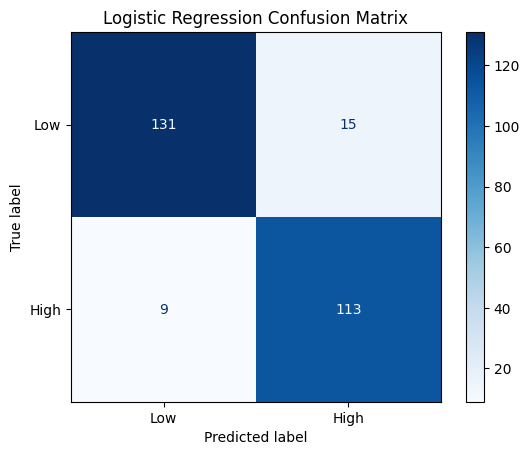

              precision    recall  f1-score   support

           0       0.94      0.90      0.92       146
           1       0.88      0.93      0.90       122

    accuracy                           0.91       268
   macro avg       0.91      0.91      0.91       268
weighted avg       0.91      0.91      0.91       268



In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# --- Re-defining dependencies to ensure they are available in this cell's scope ---
# This section is adapted from cell y7yZR-jSbwV2 and 5FFF1cSvmvW4.

# Load the insurance dataset
file_path = "insurance.csv"
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mirichoi0218/insurance",
  file_path
)

# Convert 'charges' into a binary class (High/Low) using the median as threshold
median_charge = df['charges'].median()
df['charge_class'] = (df['charges'] > median_charge).astype(int)  # 1 = High cost, 0 = Low cost

# Define features (X) and target (y)
X = df.drop(['charges', 'charge_class'], axis=1)
y = df['charge_class']

# Identify categorical and numerical features
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(include=['number']).columns

# Preprocessor for SVC (scaling needed — SVMs are sensitive to feature scale)
preprocessor_svc = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# --- End of dependency re-definition ---


print("\n--- Logistic Regression Classifier ---")
log_reg_classifier = Pipeline(steps=[('preprocessor', preprocessor_svc),
                                     ('classifier', LogisticRegression(random_state=42, solver='liblinear'))])
log_reg_classifier.fit(X_train, y_train)
y_pred_lr = log_reg_classifier.predict(X_test)

cm_lr = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:\n", cm_lr)
ConfusionMatrixDisplay(cm_lr, display_labels=['Low', 'High']).plot(cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()
print(classification_report(y_test, y_pred_lr))
